In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C7"
DTYPE="G_H"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C7_10,28,"[DATA/TRAINING/C7/C7_10/IMG_8189.HEIC, DATA/TR..."
1,C7_11,27,"[DATA/TRAINING/C7/C7_11/IMG_8248.HEIC, DATA/TR..."
2,C7_12,25,"[DATA/TRAINING/C7/C7_12/IMG_8280.HEIC, DATA/TR..."
3,C7_13,25,"[DATA/TRAINING/C7/C7_13/IMG_8311.HEIC, DATA/TR..."
4,C7_14,25,"[DATA/TRAINING/C7/C7_14/IMG_8406.HEIC, DATA/TR..."
5,C7_15,25,"[DATA/TRAINING/C7/C7_15/IMG_8343.HEIC, DATA/TR..."
6,C7_16,27,"[DATA/TRAINING/C7/C7_16/IMG_8375.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

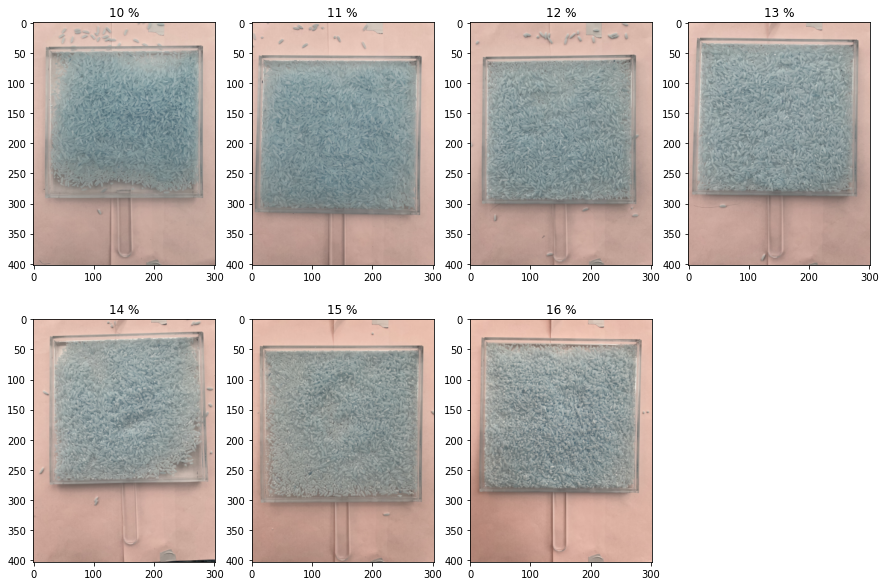

In [6]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16 %")

In [7]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [154]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [155]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8189.HEIC,10
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8190.HEIC,10
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8193.HEIC,10
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8194.HEIC,10
4,0.000292,0.000292,0.000292,0.000292,0.000292,0.000000,0.000292,0.000292,0.000292,0.000292,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8199.HEIC,10
5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8206.HEIC,10
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8210.HEIC,10
7,0.000000,0.001204,0.002107,0.002107,0.001806,0.000301,0.000602,0.000602,0.000903,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8211.HEIC,10
8,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8215.HEIC,10
9,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8216.HEIC,10


# Classification

In [156]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [157]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [158]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [159]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

### Random Forest Classifier

In [160]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [161]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.736842,0.773810,0.761905,0.767811,G_H,C7,RF_C,3,44,120,90,3
1,2,0.526316,0.595238,0.523810,0.557244,G_H,C7,RF_C,3,44,120,90,3
2,3,0.611111,0.630952,0.595238,0.612575,G_H,C7,RF_C,3,44,120,90,3
3,4,0.500000,0.500000,0.500000,0.500000,G_H,C7,RF_C,3,44,120,90,3
4,5,0.611111,0.604762,0.666667,0.634207,G_H,C7,RF_C,3,44,120,90,3
5,6,0.555556,0.666667,0.571429,0.615385,G_H,C7,RF_C,3,44,120,90,3
6,7,0.611111,0.666667,0.571429,0.615385,G_H,C7,RF_C,3,44,120,90,3
7,8,0.500000,0.690476,0.500000,0.580000,G_H,C7,RF_C,3,44,120,90,3
8,9,0.611111,0.726190,0.619048,0.668352,G_H,C7,RF_C,3,44,120,90,3
9,10,0.444444,0.442857,0.404762,0.422953,G_H,C7,RF_C,3,44,120,90,3


In [162]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C7,RF_C,0.57076,0.571429,0.597391,0.629762


### MLP Classifier

In [163]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [164]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [165]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.578947,0.583333,0.571429,0.577320,G_H,C7,MLP_C,3,44,120,90,3
1,2,0.421053,0.720238,0.428571,0.537380,G_H,C7,MLP_C,3,44,120,90,3
2,3,0.666667,0.766667,0.666667,0.713178,G_H,C7,MLP_C,3,44,120,90,3
3,4,0.388889,0.321429,0.428571,0.367347,G_H,C7,MLP_C,3,44,120,90,3
4,5,0.666667,0.728571,0.690476,0.709012,G_H,C7,MLP_C,3,44,120,90,3
5,6,0.666667,0.680952,0.595238,0.635217,G_H,C7,MLP_C,3,44,120,90,3
6,7,0.555556,0.557143,0.547619,0.552340,G_H,C7,MLP_C,3,44,120,90,3
7,8,0.500000,0.547619,0.476190,0.509413,G_H,C7,MLP_C,3,44,120,90,3
8,9,0.500000,0.600000,0.500000,0.545455,G_H,C7,MLP_C,3,44,120,90,3
9,10,0.555556,0.523810,0.547619,0.535450,G_H,C7,MLP_C,3,44,120,90,3


In [166]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C7,MLP_C,0.55,0.545238,0.568211,0.602976


### XGBoost Classifier

In [167]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [168]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.578947,0.619048,0.571429,0.594286,G_H,C7,XGB_C,3,44,120,90,3
1,2,0.421053,0.450000,0.452381,0.451187,G_H,C7,XGB_C,3,44,120,90,3
2,3,0.333333,0.523810,0.333333,0.407407,G_H,C7,XGB_C,3,44,120,90,3
3,4,0.555556,0.500000,0.547619,0.522727,G_H,C7,XGB_C,3,44,120,90,3
4,5,0.722222,0.750000,0.714286,0.731707,G_H,C7,XGB_C,3,44,120,90,3
5,6,0.555556,0.547619,0.595238,0.570437,G_H,C7,XGB_C,3,44,120,90,3
6,7,0.555556,0.571429,0.571429,0.571429,G_H,C7,XGB_C,3,44,120,90,3
7,8,0.500000,0.440476,0.452381,0.446349,G_H,C7,XGB_C,3,44,120,90,3
8,9,0.722222,0.750000,0.738095,0.744000,G_H,C7,XGB_C,3,44,120,90,3
9,10,0.555556,0.559524,0.523810,0.541078,G_H,C7,XGB_C,3,44,120,90,3


In [169]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C7,XGB_C,0.55,0.55,0.558061,0.57119


# External validation


In [170]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C7_10,5,"[DATA/TEST/C7/C7_10/IMG_8188.HEIC, DATA/TEST/C..."
1,C7_11,5,"[DATA/TEST/C7/C7_11/IMG_8249.HEIC, DATA/TEST/C..."
2,C7_12,5,"[DATA/TEST/C7/C7_12/IMG_8279.HEIC, DATA/TEST/C..."
3,C7_13,5,"[DATA/TEST/C7/C7_13/IMG_8316.HEIC, DATA/TEST/C..."
4,C7_14,5,"[DATA/TEST/C7/C7_14/IMG_8411.HEIC, DATA/TEST/C..."
5,C7_15,5,"[DATA/TEST/C7/C7_15/IMG_8344.HEIC, DATA/TEST/C..."
6,C7_16,5,"[DATA/TEST/C7/C7_16/IMG_8377.HEIC, DATA/TEST/C..."


In [171]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [172]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [173]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8188.HEIC,10
1,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8198.HEIC,10
2,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8202.HEIC,10
3,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8203.HEIC,10
4,0.0,0.000309,0.000928,0.000928,0.003712,0.000619,0.001237,0.000309,0.000000,0.000309,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8207.HEIC,10
0,0.0,0.000000,0.000000,0.000000,0.000000,0.001423,0.010248,0.001708,0.003701,0.000569,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8249.HEIC,11
1,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8251.HEIC,11
2,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8252.HEIC,11
3,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8264.HEIC,11
4,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,3,44,120,90,3,IMG_8272.HEIC,11


In [174]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [175]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [176]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [177]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [178]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.83      1.00      0.91         5
     Class 1       1.00      0.80      0.89         5
     Class 2       1.00      0.80      0.89         5
     Class 3       0.60      0.60      0.60         5
     Class 4       1.00      0.20      0.33         5
     Class 5       0.43      0.60      0.50         5
     Class 6       0.62      1.00      0.77         5

    accuracy                           0.71        35
   macro avg       0.78      0.71      0.70        35
weighted avg       0.78      0.71      0.70        35



## MLP

In [179]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [180]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.67      0.40      0.50         5
     Class 3       0.75      0.60      0.67         5
     Class 4       0.50      0.60      0.55         5
     Class 5       0.57      0.80      0.67         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.77        35
   macro avg       0.78      0.77      0.77        35
weighted avg       0.78      0.77      0.77        35



## XGBC

In [181]:
y_pred = modelXGBC.predict(X_test_scale) 

In [182]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.60      0.75         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.67      0.80      0.73         5
     Class 3       0.57      0.80      0.67         5
     Class 4       0.33      0.20      0.25         5
     Class 5       0.67      0.40      0.50         5
     Class 6       0.50      0.80      0.62         5

    accuracy                           0.66        35
   macro avg       0.68      0.66      0.64        35
weighted avg       0.68      0.66      0.64        35

